# Training the hidden Markov model

The model is in `src/gaussian_hmm.py`. It has four hidden states (Still, Standing, Walking,
Jumping) and emits eight of the twelve normalized features of a window (the choice is tested in
`model_design_checks.ipynb`), each as a Gaussian with its own average and variance per state. Training is Baum-Welch, which alternates two steps until the
log likelihood stops improving:

1. **E-step:** with the current parameters, compute the probability of every state at every window.
2. **M-step:** re-estimate the parameters as averages weighted by those probabilities.

The four training recordings are four separate sequences of 23 windows. None of them contains a
switch of activity, so counting transitions would give a switch probability of exactly zero. The
transition matrix is therefore trained with a prior: pretend counts that express the assumption
that an activity continues about 90 percent of the time and switches to each of the other three
with about 3.3 percent. The real counts are added to these pretend counts, so the trained matrix
is mostly this assumption and not something learned from switching data.

The model is started from the labeled windows (average and variance of every feature per activity)
and then refined by Baum-Welch. To show that the algorithm works without the labels, it is also
run from ten random starts.

In [1]:
import itertools
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
from gaussian_hmm import GaussianHMM

FEATURES_DIR = Path("../data/features")
FIGURES_DIR = Path("../figures")
MODELS_DIR = Path("../models")
ACTIVITIES = ["Still", "Standing", "Walking", "Jumping"]
VARIANCE_FLOOR = 1e-3
TOLERANCE = 1e-4
MAX_ITERATIONS = 200

features = pd.read_csv(FEATURES_DIR / "window_features_normalized.csv")
# the eight features chosen in model_design_checks.ipynb (the near-copies of other features are left out)
FEATURE_COLUMNS = [
    "acc_std", "acc_corr", "acc_jerk_ratio", "acc_dom_freq", "acc_low_freq_share",
    "gyro_corr", "gyro_jerk_ratio", "gyro_dom_freq",
]
sequences = [
    features[features["activity"] == a].sort_values("file")[FEATURE_COLUMNS].to_numpy()
    for a in ACTIVITIES
]
[len(s) for s in sequences], len(FEATURE_COLUMNS)

([23, 23, 23, 23], 8)

**What the output shows.** The training data are four sequences of 23 windows each, one per activity, and eight features per window.

## The implementation

The model is the class `GaussianHMM` in `src/gaussian_hmm.py`, written with numpy only. Its Viterbi decoding and the Baum-Welch training loop with the convergence check are shown here so that the algorithms can be read in the notebook. The forward and backward passes, the E-step and the M-step are in the same file, and `tests/test_gaussian_hmm.py` checks them against brute-force calculations.

In [2]:
import inspect

print(inspect.getsource(GaussianHMM.viterbi))
print(inspect.getsource(GaussianHMM.fit))

    def viterbi(self, observations):
        """Viterbi decoding in log-space: the single most likely sequence of hidden states.

        Returns the path as an integer array of length T and the log probability of that path
        together with the observations. For every window and state, the best of the incoming
        routes is kept and its origin is stored as a backpointer; the path is read out by
        following the backpointers from the best final state. Ties go to the lowest state number.
        """
        log_b = self.log_emission(observations)
        n_windows = len(log_b)
        score = np.empty_like(log_b)
        backpointer = np.zeros(log_b.shape, dtype=int)
        score[0] = self.log_start + log_b[0]
        for t in range(1, n_windows):
            routes = score[t - 1][:, None] + self.log_trans  # routes[i, j]: from state i into state j
            backpointer[t] = routes.argmax(axis=0)
            score[t] = routes.max(axis=0) + log_b[t]
        path = np.empt

**What the output shows.** `viterbi` keeps, for every window and state, the best incoming route and a backpointer, and reads the best path back from the last window. `fit` repeats the E-step and the M-step and stops when the objective (the log likelihood plus the log of the prior) rises by less than the tolerance, or after the maximum number of iterations. All probabilities are kept as logarithms.

## The prior for the transitions

Each row of pretend counts totals 20: 18 for staying in the same activity and 2 shared equally by
the three other activities. Every activity also gets one pretend start count, so no activity is
impossible as a first state.

In [3]:
N_STATES = len(ACTIVITIES)
STAY_COUNT, SWITCH_COUNT = 18.0, 2.0
trans_prior = np.full((N_STATES, N_STATES), SWITCH_COUNT / (N_STATES - 1))
np.fill_diagonal(trans_prior, STAY_COUNT)
start_prior = np.ones(N_STATES)
pd.DataFrame(trans_prior / trans_prior.sum(axis=1, keepdims=True), index=ACTIVITIES, columns=ACTIVITIES).round(4)

,Still,Standing,Walking,Jumping
Still,0.9000,0.0333,0.0333,0.0333
Standing,0.0333,0.9000,0.0333,0.0333
Walking,0.0333,0.0333,0.9000,0.0333
Jumping,0.0333,0.0333,0.0333,0.9000


**What the output shows.** The prior is the matrix of probabilities 0.9 for staying and 0.0333 for each switch, before any data is added.

## Train from the labeled start

The convergence rule: training stops when the objective (the log likelihood plus the log of the
prior) rises by less than the tolerance from one iteration to the next. In exact arithmetic it never
falls, and the check below confirms that it did not.

In [4]:
model = GaussianHMM(N_STATES, len(FEATURE_COLUMNS), variance_floor=VARIANCE_FLOOR)
model.set_parameters(
    start=np.full(N_STATES, 1 / N_STATES),
    trans=trans_prior / trans_prior.sum(axis=1, keepdims=True),
    means=np.array([s.mean(axis=0) for s in sequences]),
    variances=np.array([s.var(axis=0) for s in sequences]),
)
labeled_result = model.fit(
    sequences, max_iterations=MAX_ITERATIONS, tolerance=TOLERANCE,
    trans_prior=trans_prior, start_prior=start_prior,
)
print("converged:", labeled_result["converged"], "| iterations:", len(labeled_result["history"]),
      "| objective never decreased:", labeled_result["objective_never_decreased"])
pd.DataFrame(labeled_result["history"]).round(4)

converged: True | iterations: 3 | objective never decreased: True


,iteration,log_likelihood,objective,change
0,1,-225.2825,-265.6232,NaN
1,2,-220.3043,-262.5074,3.1158
2,3,-220.3043,-262.5074,0.0000


**What the output shows.** Training started from the labeled windows converges in 3 iterations. The log likelihood rises from -225.28 to -220.30 and then does not change, so the change is below the tolerance of 0.0001 and training stops. The objective never decreased, as it must not in exact arithmetic.

In [5]:
print("Transition matrix (row = current activity, column = next activity)")
display(pd.DataFrame(np.exp(model.log_trans), index=ACTIVITIES, columns=ACTIVITIES).round(4))
print("Start probabilities:", {a: round(float(p), 4) for a, p in zip(ACTIVITIES, np.exp(model.log_start))})
print("Variances at the floor:", int((model.variances <= VARIANCE_FLOOR + 1e-15).sum()), "of", model.variances.size)

Transition matrix (row = current activity, column = next activity)


,Still,Standing,Walking,Jumping
Still,0.9524,0.0159,0.0159,0.0159
Standing,0.0159,0.9524,0.0159,0.0159
Walking,0.0159,0.0159,0.9524,0.0159
Jumping,0.0159,0.0159,0.0159,0.9524


Start probabilities: {'Still': 0.25, 'Standing': 0.25, 'Walking': 0.25, 'Jumping': 0.25}
Variances at the floor: 0 of 32


**What the output shows.** After training, every activity stays in itself with probability 0.9524 and switches to each other activity with 0.0159. This is the prior (18 stay counts and 2 switch counts) plus the 22 stays that each recording contains and no real switch, which gives 40 of 42 for staying. The matrix is therefore mostly the assumption, not something learned from switching data. The start probabilities stay at 0.25. None of the 32 variances sits at the variance floor.

## Check on the training windows

The four recordings are glued end to end into one sequence of 92 windows with three real switches,
and decoded with Viterbi. This is the model scoring the windows it was trained on, so it shows
that the code behaves sensibly. It says nothing about unseen data.

In [6]:
all_windows = np.vstack(sequences)
true_states = np.repeat(np.arange(N_STATES), [len(s) for s in sequences])
decoded, log_probability = model.viterbi(all_windows)
runs = [(ACTIVITIES[k], len(list(g))) for k, g in itertools.groupby(decoded)]
print("windows decoded correctly:", int((decoded == true_states).sum()), "of", len(true_states))
print("decoded runs:", runs)

windows decoded correctly: 92 of 92
decoded runs: [('Still', 23), ('Standing', 23), ('Walking', 23), ('Jumping', 23)]


**What the output shows.** All 92 training windows are decoded as their true activity, in four runs of 23 windows. This only shows that the code behaves sensibly on the data it was trained on; it is not a test result.

## Does Baum-Welch work without the labels?

Ten runs start from four randomly chosen windows as the averages and the overall spread as the
variance, with the same prior and no labels. After training, each unlabeled state is matched to
the activity that fits it best, only to count how many windows are grouped as in the labels.

In [7]:
def best_match(path):
    """Windows grouped as in the labels, after matching the unlabeled states to the activities."""
    return max(
        int((np.array(order)[path] == true_states).sum())
        for order in itertools.permutations(range(N_STATES))
    )


rng = np.random.default_rng(0)
unlabeled_runs = []
for start in range(10):
    random_model = GaussianHMM(N_STATES, len(FEATURE_COLUMNS), variance_floor=VARIANCE_FLOOR)
    random_model.set_parameters(
        start=np.full(N_STATES, 1 / N_STATES),
        trans=trans_prior / trans_prior.sum(axis=1, keepdims=True),
        means=all_windows[rng.choice(len(all_windows), size=N_STATES, replace=False)],
        variances=np.tile(all_windows.var(axis=0), (N_STATES, 1)),
    )
    result = random_model.fit(sequences, max_iterations=300, tolerance=1e-6,
                              trans_prior=trans_prior, start_prior=start_prior)
    path, _ = random_model.viterbi(all_windows)
    history = result["history"]
    unlabeled_runs.append({
        "start": start, "iterations": len(history), "converged": result["converged"],
        "never decreased": result["objective_never_decreased"],
        "first log-likelihood": history[0]["log_likelihood"],
        "final log-likelihood": history[-1]["log_likelihood"],
        "windows matched (of 92)": best_match(path),
        "curve": [h["log_likelihood"] for h in history],
    })
pd.DataFrame(unlabeled_runs).drop(columns="curve").round(1)

,start,iterations,converged,never decreased,first log-likelihood,final log-likelihood,windows matched (of 92)
0,0,7,True,True,-988.2,-220.3,92
1,1,5,True,True,-851.0,-250.4,65
2,2,19,True,True,-1053.4,-555.5,60
3,3,5,True,True,-909.6,-220.3,92
4,4,6,True,True,-819.5,-204.1,91
5,5,10,True,True,-984.5,-302.2,80
6,6,14,True,True,-859.3,-291.0,67
7,7,10,True,True,-1054.4,-575.8,64
8,8,8,True,True,-1000.1,-220.3,92
9,9,5,True,True,-811.9,-251.2,88


**What the output shows.** All ten unlabeled runs converged and the objective never decreased in any of them. They end at different log likelihoods (-204.1 to -575.8) and group between 60 and 92 of the 92 windows as in the labels. Three runs reach the same -220.3 as the labeled start and match all 92 windows. One run (start 4) reaches a higher log likelihood (-204.1) but matches only 91 windows, so a higher likelihood does not always mean that the states are the activities. The other runs stop at worse local optima. For this reason the final model is started from the labeled windows.

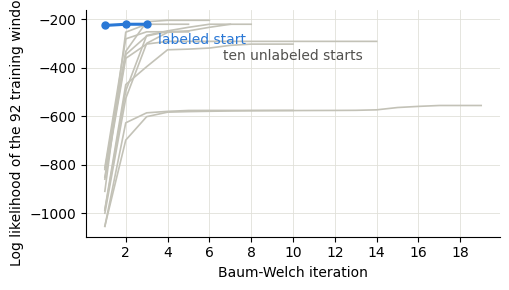

In [8]:
fig, ax = plt.subplots(figsize=(5.2, 3.0))
for run in unlabeled_runs:
    ax.plot(range(1, len(run["curve"]) + 1), run["curve"], color="#c3c2b7", linewidth=1.2)
labeled_curve = [h["log_likelihood"] for h in labeled_result["history"]]
ax.plot(range(1, len(labeled_curve) + 1), labeled_curve, color="#2a78d6", linewidth=2.2, marker="o", markersize=5)
ax.annotate("labeled start", (len(labeled_curve), labeled_curve[-1]), textcoords="offset points",
            xytext=(8, -14), color="#2a78d6")
ax.annotate("ten unlabeled starts", (6, unlabeled_runs[0]["curve"][min(5, len(unlabeled_runs[0]["curve"]) - 1)]),
            textcoords="offset points", xytext=(10, -26), color="#52514e")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Baum-Welch iteration")
ax.set_ylabel("Log likelihood of the 92 training windows")
ax.grid(color="#e1e0d9", linewidth=0.6)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "baum_welch_convergence.png", dpi=200, bbox_inches="tight")
plt.show()

**What the figure shows.** Every curve rises steeply in the first two to four iterations and then flattens, which is the behavior of the stopping rule. The labeled start (blue) begins near -225 and ends at -220.3 after 3 iterations. The ten unlabeled starts begin between about -1050 and -810 and end at different levels, from -204 to -576, and one of them needs 19 iterations. The curves do not meet, so the final model depends on the starting point.

## Save the trained model

The trained numbers are saved so the evaluation can load exactly this model.

In [9]:
MODELS_DIR.mkdir(exist_ok=True)
saved = {
    "activities": ACTIVITIES,
    "features": FEATURE_COLUMNS,
    "variance_floor": VARIANCE_FLOOR,
    "start": np.exp(model.log_start).tolist(),
    "transitions": np.exp(model.log_trans).tolist(),
    "means": model.means.tolist(),
    "variances": model.variances.tolist(),
    "training": {
        "iterations": len(labeled_result["history"]),
        "final_log_likelihood": labeled_result["history"][-1]["log_likelihood"],
        "transition_prior_counts": trans_prior.tolist(),
        "start_prior_counts": start_prior.tolist(),
        "tolerance": TOLERANCE,
    },
}
(MODELS_DIR / "hmm_parameters.json").write_text(json.dumps(saved, indent=2))
print("saved", MODELS_DIR / "hmm_parameters.json")

saved ..\models\hmm_parameters.json


**What the output shows.** The trained model was written to `models/hmm_parameters.json`: the activities and features, the start and transition probabilities, and the average and variance of every feature in every state. The evaluation notebook loads this file and nothing else, so the test recordings are scored by exactly this model.